# EDA: cleaning the South African background recordings

Owner: Pragya. Audience: the team and the write-up.

This notebook explains what is in the real South African site data and what `clean_background_windows` keeps. It uses Spark for the site-level summaries and pandas for the rest.

**Prerequisites**
- The unzipped `South_African_Real_Acoustics` folder (one Parquet file per station). The data are not in the repo and must not be committed. Set `UVNC_SA_DIR` to the folder that holds `acoustics/`, `stations.csv` and `recorders.csv`, or place it next to the repo as `../South_African_Real_Acoustics`.
- `pyspark` and a Java runtime for the Spark section. The other sections need only pandas, numpy and matplotlib.
- `Test.csv` in the repo root. It is used here only to compare layout and levels. It is never used to fit, calibrate or build training examples.

**Outline**
1. Find the data and load station metadata.
2. Spark summaries per site and recorder.
3. Rows removed by each cleaning rule.
4. Windows per site.
5. Recorder levels.
6. Recording gaps and duty cycles.
7. Spectra against `Test.csv`.
8. Hidden minutes in `Test.csv`.
9. Loud values.
10. Findings and open decisions.

## 1. Setup and data location

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "src" / "uvnc").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from uvnc.cleaning import (
    BAND_CENTRES, RAW_BANDS, WINDOW_COLUMNS, clean_background_windows,
    load_site, row_loss_table, spark_site_summaries,
)

candidates = [os.environ.get("UVNC_SA_DIR"),
              ROOT.parent / "South_African_Real_Acoustics",
              ROOT / "data" / "South_African_Real_Acoustics"]
DATA = next((Path(c) for c in candidates if c and (Path(c) / "acoustics").exists()), None)
if DATA is None:
    raise FileNotFoundError("Set UVNC_SA_DIR to the folder that contains acoustics/.")
PATHS = sorted((DATA / "acoustics").glob("*.parquet"))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("data:", DATA)
print(len(PATHS), "station files")

## 2. Station metadata

`stations.csv` lists each station's span of export timestamps and `recorders.csv` lists each recorder. A station can have several recorders deployed at different times. Their levels turn out to differ a lot (section 5).

In [2]:
stations = pd.read_csv(DATA / "stations.csv")
recorders = pd.read_csv(DATA / "recorders.csv")
stations[["site", "minutes", "first_export_timestamp", "last_export_timestamp"]]

,site,minutes,first_export_timestamp,last_export_timestamp
0,1 Richards Bay,1001174,2017-05-09 00:00:02,2024-05-25 23:59:00
1,10 Sea Point,3660,2018-10-11 10:00:02,2018-10-13 23:59:00
2,13 Saldhana Bay,134732,2022-03-22 00:00:00,2023-05-29 04:34:00
3,2 Durban,44640,2025-10-28 00:00:00,2025-12-06 23:59:00
4,3 Cape_Recife,5928,2024-03-05 00:00:00,2024-03-23 23:12:00
5,4 Bird Island,47552,2022-03-21 05:59:58,2024-06-29 23:59:00
6,5 St Croix Island,250717,2022-04-05 00:00:00,2025-09-20 06:00:00
7,6 Riy_Banks,4121,2024-03-05 00:00:00,2024-04-05 23:12:00
8,7 St_Francis,169488,2015-04-21 00:00:00,2018-02-28 14:24:00
9,9 Fish Hoek,53767,2016-09-13 00:00:02,2021-09-28 12:45:00


## 3. Spark summaries per site and recorder

Spark reads all Parquet files in parallel. `share_full_minute` is the share of rows lasting 55 to 65 seconds. `share_flat` is the share of rows whose 25 bands span less than 6 dB, which is how a frozen recorder looks.

In [ ]:
try:
    summary = spark_site_summaries(PATHS)
    summary["short_recorder"] = summary["recorder"].str.slice(0, 20)
    display_cols = ["site", "short_recorder", "rows", "first_t", "last_t", "share_full_minute",
                    "share_flat", "median_level_db", "min_db", "max_db"]
    show = summary[display_cols].copy()
    numeric = show.select_dtypes("number").columns
    show[numeric] = show[numeric].round(3)
except Exception as exc:  # no Java or no pyspark on this machine
    summary, show = None, None
    print("Spark unavailable here:", type(exc).__name__, exc)
show

,site,short_recorder,rows,first_t,last_t,share_full_minute,share_flat,median_level_db,min_db,max_db
0,1 Richards Bay,201383949_Richards_B,492310,2017-05-09 00:00:02,2019-10-05 16:06:00,0.987,0.000,61.028,28.500000,146.800003
1,1 Richards Bay,5708_Richards_Bay_57,160798,2020-10-02 00:00:00,2021-11-28 01:48:00,0.981,0.004,78.088,-156.500000,154.399994
2,1 Richards Bay,7005_Richards_Bay_70,348066,2022-10-04 00:00:00,2024-05-25 23:59:00,0.982,0.012,81.224,25.000000,154.699997
3,10 Sea Point,ST300_201650217_ST20,3660,2018-10-11 10:00:02,2018-10-13 23:59:00,1.000,0.000,56.876,36.099998,105.500000
4,13 Saldhana Bay,ST300_5344_ST5344.1.,60912,2022-03-22 00:00:00,2022-05-28 23:59:00,1.000,0.000,61.640,39.700001,139.100006
5,13 Saldhana Bay,ST500_5350_ST500_535,73820,2023-03-07 00:00:00,2023-05-29 04:34:00,1.000,0.000,64.364,37.400002,137.800003
6,2 Durban,8230_ST600_8230.1.48,44640,2025-10-28 00:00:00,2025-12-06 23:59:00,1.000,0.000,72.092,39.000000,144.199997
7,3 Cape_Recife,8210_ST600_8210.1.48,5928,2024-03-05 00:00:00,2024-03-23 23:12:00,1.000,0.000,74.924,50.799999,125.699997
8,4 Bird Island,URN.BirdIsland.2022_,46472,2022-03-21 05:59:58,2022-09-06 05:59:00,0.999,0.000,89.664,53.500000,174.199997
9,4 Bird Island,URN_8321_8321.1.1200,1080,2024-06-29 06:00:00,2024-06-29 23:59:00,1.000,0.000,58.628,38.000000,122.800003


## 4. Rows removed by each cleaning rule

Each rule is counted separately, so one row can fail more than one rule. This is the table to cite in the write-up. The loop also cuts the windows we use in the rest of the notebook.

In [4]:
loss, parts, run_stats = [], [], []
for p in PATHS:
    raw = load_site(p)
    row = row_loss_table(raw)
    win = clean_background_windows(raw)
    row["site"] = raw["site"].iloc[0]
    row["windows"] = len(win)
    row["rows_in_windows"] = len(win) * 15
    loss.append(row)
    parts.append(win)

    # Run lengths of strictly consecutive minutes on the raw rows, per recorder.
    s = raw.sort_values(["recorder", "t"])
    gap = s["t"].diff().dt.total_seconds()
    seg = (s["recorder"].ne(s["recorder"].shift()) | ~gap.between(55, 65)).cumsum()
    runs = seg.value_counts()
    run_stats.append({"site": raw["site"].iloc[0], "runs": len(runs),
                      "median_run_min": runs.median(), "max_run_min": runs.max(),
                      "share_rows_in_runs_ge15": runs[runs >= 15].sum() / len(s),
                      "all_runs": runs.to_numpy()})
    del raw

loss = pd.DataFrame(loss).set_index("site")
windows = pd.concat(parts, ignore_index=True)
meta = windows.drop(columns=WINDOW_COLUMNS)
windows = pd.concat([meta, windows[WINDOW_COLUMNS].astype("float32")], axis=1)
run_stats = pd.DataFrame(run_stats).set_index("site")
loss

,rows,fail_duration_ok,fail_finite_25_bands,fail_spread_ok,fail_level_ok,fail_not_frozen,rows_kept,windows,rows_in_windows
site,,,,,,,,,
1 Richards Bay,1001174,15713,0,4854,654,649,980724,52134,782010
2 Durban,44640,0,0,0,0,0,44640,2976,44640
3 Cape_Recife,5928,0,0,0,0,0,5928,0,0
4 Bird Island,47552,32,0,0,0,0,47520,3168,47520
5 St Croix Island,250717,130,0,3,0,0,250584,16698,250470
6 Riy_Banks,4121,0,0,0,0,0,4121,0,0
7 St_Francis,169488,1,0,44,0,0,169443,3371,50565
9 Fish Hoek,53767,1014,0,71,0,0,52682,294,4410
10 Sea Point,3660,0,0,0,0,0,3660,244,3660


## 5. Windows per site

,windows,share_of_all,rows,share_rows_used
site,,,,
1 Richards Bay,52134,0.594,1001174,0.781
5 St Croix Island,16698,0.190,250717,0.999
13 Saldhana Bay,8867,0.101,134732,0.987
7 St_Francis,3371,0.038,169488,0.298
4 Bird Island,3168,0.036,47552,0.999
2 Durban,2976,0.034,44640,1.000
9 Fish Hoek,294,0.003,53767,0.082
10 Sea Point,244,0.003,3660,1.000
6 Riy_Banks,0,0.000,4121,0.000


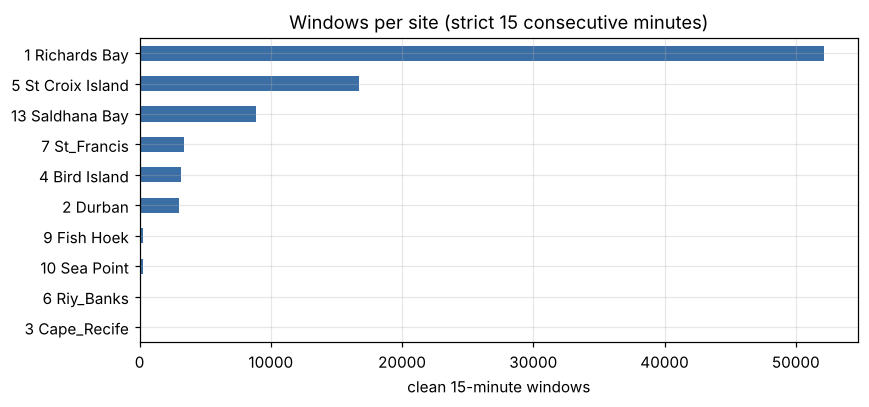

In [5]:
per_site = (windows.groupby("site").size().reindex(loss.index).fillna(0).astype(int))
per_site_share = (per_site / per_site.sum()).round(3)
table = pd.DataFrame({"windows": per_site, "share_of_all": per_site_share,
                      "rows": loss["rows"], "share_rows_used": (loss["rows_in_windows"] / loss["rows"]).round(3)})
display(table.sort_values("windows", ascending=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
per_site.sort_values().plot.barh(ax=ax, color="#3b6ea5")
ax.set_xlabel("clean 15-minute windows"); ax.set_ylabel("")
ax.set_title("Windows per site (strict 15 consecutive minutes)")
plt.tight_layout(); plt.show()

## 6. Recorder levels

Recorders at the same site can sit tens of dB apart, which matters for cross-validation. The boxplot shows each window's mean level (average over its 375 values) per recorder.

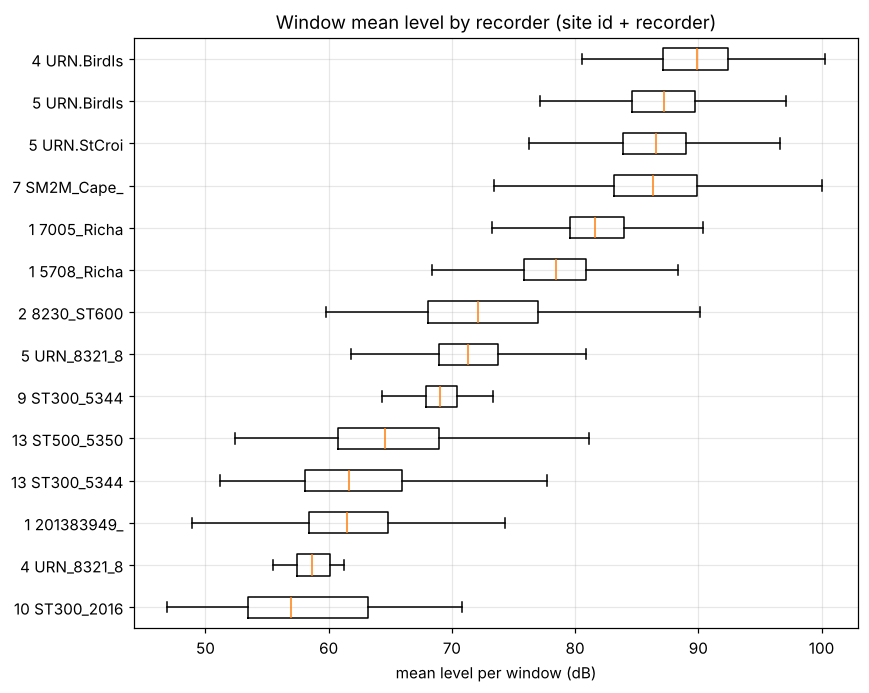

,min,max,range_db
site,,,
4 Bird Island,58.700001,89.900002,31.200001
1 Richards Bay,61.500000,81.599998,20.100000
5 St Croix Island,71.300003,87.199997,15.900000
13 Saldhana Bay,61.700001,64.599998,2.900000
2 Durban,72.099998,72.099998,0.000000
10 Sea Point,57.000000,57.000000,0.000000
7 St_Francis,86.400002,86.400002,0.000000
9 Fish Hoek,69.000000,69.000000,0.000000


In [6]:
windows["mean_level_db"] = windows[WINDOW_COLUMNS].mean(axis=1)
windows["rec_label"] = windows["site_id"].astype(str) + " " + windows["recorder"].str.slice(0, 10)
order = windows.groupby("rec_label")["mean_level_db"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 0.35 * len(order) + 1.5))
ax.boxplot([windows.loc[windows["rec_label"] == r, "mean_level_db"] for r in order],
           vert=False, showfliers=False)
ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order)
ax.set_xlabel("mean level per window (dB)")
ax.set_title("Window mean level by recorder (site id + recorder)")
plt.tight_layout(); plt.show()
rec_spread = windows.groupby(["site", "recorder"])["mean_level_db"].median().groupby("site").agg(["min", "max"])
rec_spread["range_db"] = rec_spread["max"] - rec_spread["min"]
rec_spread.round(1).sort_values("range_db", ascending=False)

## 7. Gaps and duty cycles

Some recorders do not run continuously. A strict window needs 15 minutes with no gap, so these sites lose windows. `share_rows_in_runs_ge15` is the share of raw rows that sit in an unbroken run of at least 15 minutes.

,runs,median_run_min,max_run_min,share_rows_in_runs_ge15
site,,,,
1 Richards Bay,15033,59.0,24720,0.993
2 Durban,2,22320.0,37440,1.000
3 Cape_Recife,456,13.0,13,0.000
4 Bird Island,68,360.0,1440,0.999
5 St Croix Island,205,1440.0,83040,1.000
6 Riy_Banks,317,13.0,13,0.000
7 St_Francis,27154,5.0,15,0.298
9 Fish Hoek,10259,5.0,1079,0.084
10 Sea Point,2,1830.0,3300,1.000


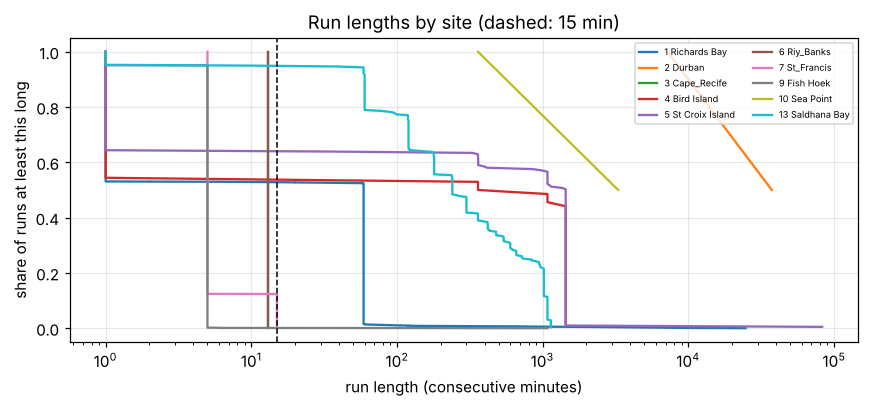

In [7]:
view = run_stats.drop(columns="all_runs").round(3)
display(view)

fig, ax = plt.subplots(figsize=(8, 3.8))
for site, runs in run_stats["all_runs"].items():
    r = np.sort(runs)
    ax.plot(r, 1 - np.arange(len(r)) / len(r), label=site)
ax.axvline(15, color="k", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("run length (consecutive minutes)")
ax.set_ylabel("share of runs at least this long"); ax.set_title("Run lengths by site (dashed: 15 min)")
ax.legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()

## 8. Spectra against `Test.csv`

For each site, the median level in each of the 25 bands, averaged over minutes. The black line is the median of `Test.csv`. This is a descriptive comparison only. Nothing from `Test.csv` is used for fitting.

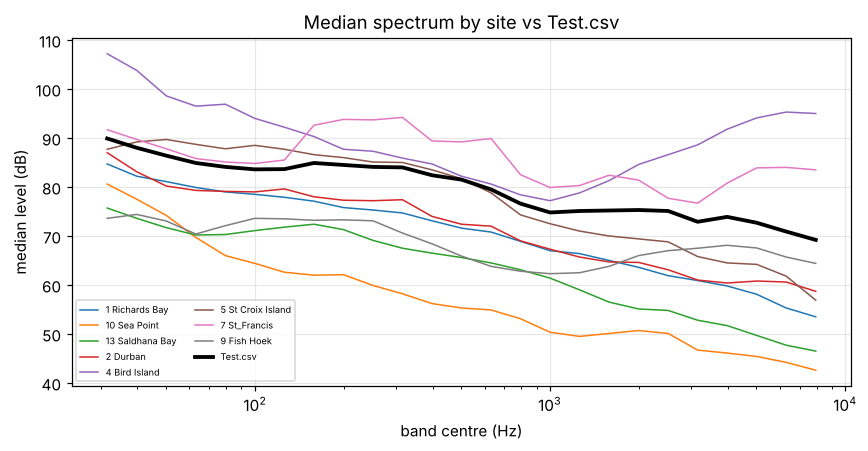

Test.csv level range (dB): 29.3 to 152.9
Cleaned windows level range (dB): 28.5 to 174.2


In [8]:
test = pd.read_csv(ROOT / "Test.csv")
assert list(test.columns[1:]) == WINDOW_COLUMNS, "Test.csv columns differ from cleaned windows"
freqs = np.array([float(c) for c in BAND_CENTRES])

def band_median(frame):
    cube = frame[WINDOW_COLUMNS].to_numpy(dtype=np.float64).reshape(len(frame), 15, 25)
    return np.nanmedian(cube.reshape(-1, 25), axis=0)

fig, ax = plt.subplots(figsize=(8, 4.2))
for site, grp in windows.groupby("site"):
    ax.plot(freqs, band_median(grp), lw=1, label=site)
ax.plot(freqs, band_median(test), "k", lw=2.5, label="Test.csv")
ax.set_xscale("log"); ax.set_xlabel("band centre (Hz)"); ax.set_ylabel("median level (dB)")
ax.set_title("Median spectrum by site vs Test.csv"); ax.legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

print("Test.csv level range (dB): %.1f to %.1f" % (np.nanmin(test[WINDOW_COLUMNS].to_numpy()), np.nanmax(test[WINDOW_COLUMNS].to_numpy())))
print("Cleaned windows level range (dB): %.1f to %.1f" % (windows[WINDOW_COLUMNS].to_numpy().min(), windows[WINDOW_COLUMNS].to_numpy().max()))

## 9. Hidden minutes in `Test.csv`

The cleaned training windows have no blanks because the recorders never leave the 25 bands blank. The blanks in `Test.csv` are whole hidden minutes. The count per window is below, so masking in the training pipeline can be compared with it.

windows by number of hidden minutes: {0: 775, 1: 717, 2: 7, 3: 1} | minutes with only some bands blank: 0


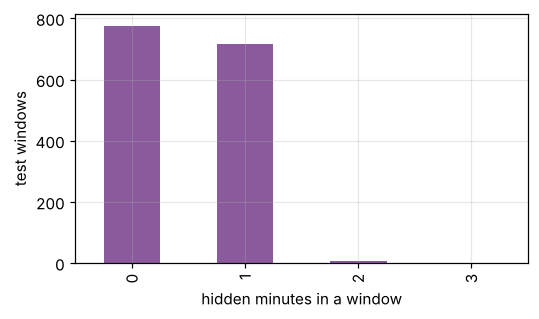

In [9]:
cube = test[WINDOW_COLUMNS].to_numpy(dtype=np.float64).reshape(len(test), 15, 25)
hidden_min = np.isnan(cube).all(axis=2).sum(axis=1)
partial = (np.isnan(cube).any(axis=2) & ~np.isnan(cube).all(axis=2)).sum()
counts = pd.Series(hidden_min).value_counts().sort_index()
print("windows by number of hidden minutes:", counts.to_dict(), "| minutes with only some bands blank:", int(partial))
fig, ax = plt.subplots(figsize=(5, 3))
counts.plot.bar(ax=ax, color="#8a5a9c"); ax.set_xlabel("hidden minutes in a window"); ax.set_ylabel("test windows")
plt.tight_layout(); plt.show()

## 10. Loud values

Some readings exceed 130 dB. They are kept in the cleaned windows because `Test.csv` also contains high values. The table shows how many windows contain one.

In [10]:
vals = windows[WINDOW_COLUMNS].to_numpy()
windows["any_gt_130"] = (vals > 130).any(axis=1)
loud = windows.groupby("site")["any_gt_130"].agg(["sum", "mean"]).rename(columns={"sum": "windows_with_value_over_130dB", "mean": "share"})
loud["max_db"] = windows.groupby("site")[WINDOW_COLUMNS].max().max(axis=1)
loud.round(3).sort_values("windows_with_value_over_130dB", ascending=False)

,windows_with_value_over_130dB,share,max_db
site,,,
1 Richards Bay,567,0.011,154.399994
4 Bird Island,255,0.080,174.199997
5 St Croix Island,121,0.007,152.100006
7 St_Francis,106,0.031,142.000000
13 Saldhana Bay,17,0.002,139.100006
2 Durban,14,0.005,144.199997
9 Fish Hoek,10,0.034,144.300003
10 Sea Point,0,0.000,105.500000


## 11. Findings and open decisions

All numbers below come from the cells above.

**What cleaning removes.** Of 1,715,779 raw rows, 1,694,004 pass every rule (98.7%). Richards Bay accounts for most of the removed rows: 15,713 are not a full minute, 4,854 are flat, 654 fall below 20 dB, and 649 repeat the previous row. The 25 common bands are never blank in the raw data (`fail_finite_25_bands` is 0 everywhere).

**Windows.** The cleaning yields 87,752 windows from 8 of the 10 sites. Cape Recife and Riy Banks give none: their recorders run for 13 minutes at a time (median run 13 minutes, maximum 13). St Francis puts 29.8% of its rows into runs of 15 minutes or more, and Fish Hoek 8.4%.

**Site imbalance.** Richards Bay is 59.4% of windows, St Croix Island 19.0% and Saldhana Bay 10.1%, so three sites hold 88.5%. Sea Point (244 windows) and Fish Hoek (294) are tiny.

**Recorder levels.** Recorders at one site differ by up to 31 dB (Bird Island), 20 dB (Richards Bay) and 16 dB (St Croix Island). The same full recorder name appears at two sites in five cases, for example `URN_8321_8321.1.12000` at Bird Island (median 58.6 dB) and St Croix Island (71.3 dB), and `URN.BirdIsland.2022_6509.1.24000` at both as well. So a recorder name is not a unique key. Use (site, recorder) when grouping. If a recorder physically moved between sites, holding out whole sites still leaves the same hardware in training.

**Levels against `Test.csv`.** Test levels run from 29.3 to 152.9 dB and the cleaned windows from 28.5 to 174.2 dB. The site spectra bracket the test spectrum, with no single site matching it.

**Hidden minutes.** In `Test.csv`, 775 windows hide no minute, 717 hide one, 7 hide two and 1 hides three. No minute has only some bands blank. The cleaned windows have no blanks at all, so hidden minutes have to be added by the masking step.

**Loud values.** Windows with a value above 130 dB: Bird Island 255 (8.0%, maximum 174.2 dB), Richards Bay 567 (1.1%), St Croix Island 121. They are kept.

**Open decisions**
1. Keep strict 15 consecutive minutes, or stitch bursts at duty-cycled sites? Stitching would add windows with gaps inside them.
2. Cap or reweight windows per site before training? Who owns it, cleaning or modelling?
3. Keep or clip readings above 130 dB?
4. Cross-validation groups: site alone, or site plus recorder? Station metadata also says deployment assignment should be verified.